# PathSnap — Data cleaning

This notebook cleans the raw PathSnap trips (train + student_test) and saves one cleaned table per trip.
It implements cleaning steps **C1–C10** from the dataset briefing (Section 14).

**Ground rules**
- Nothing is deleted from the raw data. Every removal is a **flag with a reason code**, so it can be audited or undone.
- Steps marked **always** use only GPS + map, so the API can run them on evaluator trips.
- Steps marked **training only** use the reference route, so they are used only to build training data.
- All thresholds were chosen from the train data during exploration and are fixed here.

**Output** (in `data_clean/<partition>/<trip>/`):
- `fixes.csv.gz`: one row per GPS fix, with derived columns, flags and labels
- `arcs.csv.gz`: one row per road arc, with length, bearing and a candidate-eligible flag
- `projection.json`: the projection origin, so prediction uses the exact same coordinates
- `data_clean/cleaning_summary.csv`: counts per rule for every trip

## 0. Setup: imports, paths and thresholds

In [1]:
import glob, json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = "../Student folder"   # raw data: train/ and student_test/ trip folders
OUT_DIR = "../data_clean"        # where cleaned files are written
PARTITIONS = ["train", "student_test"]

# Thresholds (from the exploratory analysis of the train data)
GAP_S = 60.0              # C2: a pause longer than this starts a new segment
JUMP_MS = 250 / 3.6       # C8: speed in AND out above 250 km/h marks a position jump (m/s)
FAR_M = 50.0              # C4/C6/C7: fixes further than this from their label are unreliable for training
DWELL_WIN_S = 120         # a dwell = at least 120 s ...
DWELL_RAD_M = 30          # ... during which all fixes stay within 30 m of their centre
DWELL_KEEP_EVERY = 10     # C4: keep 1 in 10 fixes inside on-road dwells
MIN_MOVE_M = 4.0          # heading is only defined if the neighbouring fixes are more than 4 m apart
R_EARTH = 6371008.8       # mean Earth radius in metres

## 1. Loading one trip

Each trip folder has four headerless, whitespace-separated files:

| file | columns | meaning |
|---|---|---|
| `.track` | lon, lat, t | GPS fixes in time order |
| `.nodes` | lon, lat | map points; row k = node k |
| `.arcs` | from_node, to_node | directed road pieces; row k = arc k |
| `.route` | arc_id | the arcs actually driven, in order |

In [2]:
def load_trip(trip_dir):
    """Read the four files of one trip into numpy arrays."""
    t = os.path.basename(trip_dir)
    read = lambda ext, dtype: np.loadtxt(f"{trip_dir}/{t}.{ext}", dtype=dtype, ndmin=2)
    track = read("track", float)       # (N, 3): lon, lat, time
    nodes = read("nodes", float)       # (num_nodes, 2): lon, lat
    arcs = read("arcs", np.int64)      # (num_arcs, 2): from_node, to_node
    route = np.loadtxt(f"{trip_dir}/{t}.route", dtype=np.int64, ndmin=1)  # arc ids in order
    return t, track, nodes, arcs, route

# quick look at one trip
t, track, nodes, arcs, route = load_trip(f"{DATA_DIR}/train/00000001")
print(f"trip {t}: {len(track)} fixes, {len(nodes)} nodes, {len(arcs)} arcs, {len(route)} route arcs")
track[:3]

trip 00000001: 1315 fixes, 88809 nodes, 165790 arcs, 525 route arcs


array([[ 8.595203, 49.844053,  1.      ],
       [ 8.595294, 49.844441,  2.      ],
       [ 8.595352, 49.844883,  3.      ]])

## 2. Helper functions

- **`project`**: converts longitude/latitude (degrees) to flat x/y in metres around a centre point. Degrees are not
  distances (one degree of longitude is about 111 km at the equator but only 53 km at 61°N), so every distance, speed
  and heading below uses these metres. At trip scale (at most about 75 km) this simple projection is accurate enough.
- **`point_segment_distance`**: shortest distance from each point to each arc. Arcs are straight segments, so we
  measure to the line, not to its end nodes.
- **`dwell_mask`**: finds "standing still" fixes: every fix inside a window of at least 120 s whose fixes all stay
  within 30 m of their centre.
- **`order_aware_labels`**: assigns each fix to a route arc (Section 2 below explains why this is needed).

In [3]:
def project(lon, lat, lon0, lat0):
    """Local equirectangular projection to metres around (lon0, lat0)."""
    x = np.radians(lon - lon0) * R_EARTH * np.cos(np.radians(lat0))
    y = np.radians(lat - lat0) * R_EARTH
    return x, y


def point_segment_distance(px, py, ax, ay, bx, by):
    """Distance from point(s) P to segment(s) AB (numpy broadcasting). Returns (distance, t),
    where t in [0, 1] is where the closest point lies along the segment."""
    dx, dy = bx - ax, by - ay
    L2 = dx * dx + dy * dy
    t = np.where(L2 > 0, ((px - ax) * dx + (py - ay) * dy) / np.where(L2 > 0, L2, 1), 0.0)
    t = np.clip(t, 0, 1)
    return np.hypot(px - (ax + t * dx), py - (ay + t * dy)), t


def dwell_mask(x, y, ts, win=DWELL_WIN_S, rad=DWELL_RAD_M):
    """True for fixes inside any >= win-second window whose fixes all stay within rad metres of the window centre."""
    n = len(x)
    mark = np.zeros(n, bool)
    j = 0
    for i in range(n):                      # sliding window [i, j)
        while j < n and ts[j] - ts[i] <= win:
            j += 1
        if ts[j - 1] - ts[i] >= win * 0.9:  # window long enough
            wx, wy = x[i:j], y[i:j]
            if np.hypot(wx - wx.mean(), wy - wy.mean()).max() < rad:
                mark[i:j] = True
    return mark

### Order-aware labels

The `.route` file lists the arcs driven, but **not when**. To train and score per fix we need a label for every fix.

We compute the distance `D[i, j]` from every fix *i* to every route arc *j*. Then we choose an assignment in which the
route position **never goes backwards** in time (a car moves forward along its route) and the total distance is as
small as possible. Dynamic programming solves this exactly:

`cost[i, j] = D[i, j] + min(cost[i-1, k] for k <= j)`

A running prefix-minimum makes each step O(M), so the whole trip costs O(N·M). We then trace back the best path.

Why not just take the nearest route arc? When a route goes out and back along the same street, a fix on the way out
is equally close to the twin arc used on the way back. In some trips the nearest-arc rule mislabels 23–43% of fixes.

In [4]:
def order_aware_labels(D):
    """D: (N fixes, M route arcs) distances. Returns, for each fix, a route position that never decreases
    over time and minimises the total distance."""
    N, M = D.shape
    back = np.empty((N, M), dtype=np.int32)  # back-pointers for the trace-back
    cost = D[0].astype(np.float64)
    back[0] = np.arange(M)
    idx = np.arange(M)
    for i in range(1, N):
        prefix_min = np.minimum.accumulate(cost)                   # best cost of any k <= j
        is_new_min = np.r_[True, cost[1:] < prefix_min[:-1]]
        argmin_k = np.maximum.accumulate(np.where(is_new_min, idx, 0))  # where that minimum was reached
        back[i] = argmin_k
        cost = prefix_min + D[i]
    labels = np.empty(N, dtype=np.int64)
    labels[-1] = int(np.argmin(cost))
    for i in range(N - 1, 0, -1):                                  # trace back
        labels[i - 1] = back[i, labels[i]]
    return labels

## 3. Cleaning one trip, step by step

The function below runs every step on one trip. The comments name the step (C1–C10). In short:

| step | what | scope |
|---|---|---|
| C1 | project to metres | always |
| C2 | new segment after pauses over 60 s | always |
| C3 | speeds from real time differences | always |
| — | heading from the previous to the next fix | always |
| C4 | detect dwells; drop parked off-road fixes; thin on-road dwells to 1 in 10 | training only |
| C5 | flag dwell fixes (the API gives them the last moving arc) | always |
| C6 | drop fixes more than 50 m from their label | training only |
| C7 | drop fixes beyond the route's start/end | training only |
| C8 | flag position jumps (over 250 km/h in and out) | always |
| C9 | exclude self-loop and zero-length arcs from candidates | always |
| C10 | keep route breaks, loops and U-turns; labels are built on them | — |

Training filters are applied **in order**, and each fix gets the **first** reason that applies, so the counts add up.

In [5]:
def clean_trip(partition, trip_dir):
    t, track, nodes, arcs, route = load_trip(trip_dir)
    lon, lat, ts = track[:, 0], track[:, 1], track[:, 2]
    n = len(track)

    # ---- C1: project to metres, centred on the trip's median position ----
    lon0, lat0 = float(np.median(lon)), float(np.median(lat))
    x, y = project(lon, lat, lon0, lat0)
    nx, ny = project(nodes[:, 0], nodes[:, 1], lon0, lat0)

    # ---- C3: real time differences and speeds (m/s) ----
    dt = np.r_[np.nan, np.diff(ts)]                       # first fix has no previous fix
    step = np.r_[np.nan, np.hypot(np.diff(x), np.diff(y))]
    speed_in = step / dt                                  # speed arriving at this fix
    speed_out = np.r_[speed_in[1:], np.nan]               # speed leaving this fix

    # ---- C2: segment id increases after every pause longer than GAP_S ----
    segment = np.cumsum(np.r_[True, np.diff(ts) > GAP_S]) - 1

    # ---- heading: direction from previous to next fix, not across segment boundaries ----
    prev_i = np.r_[0, np.arange(n - 1)]
    next_i = np.r_[np.arange(1, n), n - 1]
    prev_i = np.where(segment[prev_i] == segment, prev_i, np.arange(n))
    next_i = np.where(segment[next_i] == segment, next_i, np.arange(n))
    hx, hy = x[next_i] - x[prev_i], y[next_i] - y[prev_i]
    heading = np.degrees(np.arctan2(hx, hy)) % 360        # 0 = north, 90 = east
    heading_ok = np.hypot(hx, hy) > MIN_MOVE_M            # undefined when (almost) not moving

    # ---- C4/C5: standing-still detection ----
    dwell = dwell_mask(x, y, ts)

    # ---- C8: position jump = implausible speed both into and out of the fix ----
    jump = (np.nan_to_num(speed_in) > JUMP_MS) & (np.nan_to_num(speed_out) > JUMP_MS)

    # ---- C9: arc properties and candidate eligibility ----
    fr, to = arcs[:, 0], arcs[:, 1]
    arc_len = np.hypot(nx[to] - nx[fr], ny[to] - ny[fr])
    arc_bearing = np.degrees(np.arctan2(nx[to] - nx[fr], ny[to] - ny[fr])) % 360
    pair = fr * len(nodes) + to                           # unique code per (from, to)
    has_twin = np.isin(to * len(nodes) + fr, pair)        # reverse arc exists, so the road is two-way
    duplicate = pd.Series(pair).duplicated().values       # same (from, to) seen before
    eligible = (fr != to) & (arc_len > 0.01)              # no self-loops, no zero-length arcs

    # ---- labels: order-aware assignment of fixes to route arcs ----
    rf, rt = fr[route], to[route]
    D, _ = point_segment_distance(x[:, None], y[:, None], nx[rf][None], ny[rf][None], nx[rt][None], ny[rt][None])
    D = D.astype(np.float32)
    pos = order_aware_labels(D)                           # route position for each fix
    d_label = D[np.arange(n), pos]                        # distance to the assigned arc
    label_arc = route[pos]                                # the arc id = the label
    d_route = D.min(1)                                    # distance to the nearest route arc

    # ---- training filters (first matching reason wins) ----
    reason = np.full(n, "", dtype=object)
    counts = {}
    def mark(mask, why):
        m = mask & (reason == "")
        reason[m] = why
        counts[why] = int(m.sum())

    mark(jump, "C8_jump")                                          # bad position
    mark(dwell & (d_route > FAR_M), "C4_offroad_dwell")            # parked away from any route road
    far = d_label > FAR_M
    head = np.zeros(n, bool); tail = np.zeros(n, bool)             # C7: far-off runs at the very start/end
    i = 0
    while i < n and far[i] and pos[i] == 0:
        head[i] = True; i += 1
    i = n - 1
    while i >= 0 and far[i] and pos[i] == len(route) - 1:
        tail[i] = True; i -= 1
    mark(head | tail, "C7_beyond_route")
    mark(far, "C6_far_from_label")                                 # label doubtful
    run_id = np.cumsum(np.r_[True, dwell[1:] != dwell[:-1]])       # consecutive dwell / non-dwell runs
    k_in_run = pd.Series(np.arange(n)).groupby(run_id).cumcount().values
    mark(dwell & (k_in_run % DWELL_KEEP_EVERY != 0), "C4_dwell_thinned")  # keep 1 in 10 standing fixes
    keep_train = reason == ""

    # ---- assemble outputs ----
    fixes = pd.DataFrame({
        "fix": np.arange(n), "lon": lon, "lat": lat, "t": ts, "x": x.round(3), "y": y.round(3),
        "dt": dt, "segment": segment, "speed_in": speed_in.round(3), "speed_out": speed_out.round(3),
        "heading": heading.round(2), "heading_ok": heading_ok, "dwell": dwell, "jump": jump,
        "label_arc": label_arc, "label_route_pos": pos, "d_label": d_label.round(3), "d_route": d_route.round(3),
        "keep_train": keep_train, "drop_reason": reason})
    arcs_df = pd.DataFrame({"arc": np.arange(len(arcs)), "from": fr, "to": to, "length_m": arc_len.round(3),
                            "bearing": arc_bearing.round(2), "has_twin": has_twin, "duplicate": duplicate,
                            "candidate_eligible": eligible})
    summary = dict(partition=partition, trip=t, fixes=n, segments=int(segment.max() + 1),
                   dwell_fixes=int(dwell.sum()), jump_fixes=int(jump.sum()), **counts,
                   kept_for_training=int(keep_train.sum()), arcs=len(arcs),
                   arcs_excluded_C9=int((~eligible).sum()), duplicate_arcs=int(duplicate.sum()))
    return fixes, arcs_df, {"lon0": lon0, "lat0": lat0}, summary

### Try it on one trip first

In [6]:
fixes, arcs_df, proj, summary = clean_trip("train", f"{DATA_DIR}/train/00000033")
print(summary)
fixes.head()

{'partition': 'train', 'trip': '00000033', 'fixes': 5844, 'segments': 1, 'dwell_fixes': 4832, 'jump_fixes': 0, 'C8_jump': 0, 'C4_offroad_dwell': 3355, 'C7_beyond_route': 0, 'C6_far_from_label': 85, 'C4_dwell_thinned': 1332, 'kept_for_training': 1072, 'arcs': 6360, 'arcs_excluded_C9': 0, 'duplicate_arcs': 2}


,fix,lon,lat,t,x,y,dt,segment,speed_in,speed_out,heading,heading_ok,dwell,jump,label_arc,label_route_pos,d_label,d_route,keep_train,drop_reason
0,0,18.718013,50.018685,1.0,1463.492,-1148.312,NaN,0,NaN,11.588,316.83,True,False,False,5466,0,1.288,1.288,True,
1,1,18.717902,50.018761,2.0,1455.563,-1139.861,1.0,0,11.588,15.325,308.65,True,False,False,5466,0,1.957,1.957,True,
2,2,18.717721,50.018835,3.0,1442.634,-1131.632,1.0,0,15.325,9.078,291.26,True,False,False,5466,0,2.469,2.469,True,
3,3,18.717594,50.018838,4.0,1433.562,-1131.299,1.0,0,9.078,20.640,287.00,True,False,False,5466,0,1.857,1.857,True,
4,4,18.717329,50.018912,5.0,1414.633,-1123.070,1.0,0,20.640,14.705,294.97,True,False,False,5466,0,4.396,4.396,True,


Trip 033 is one of the two "parked car" trips: most fixes are dropped as `C4_offroad_dwell`. Plotting it shows why.

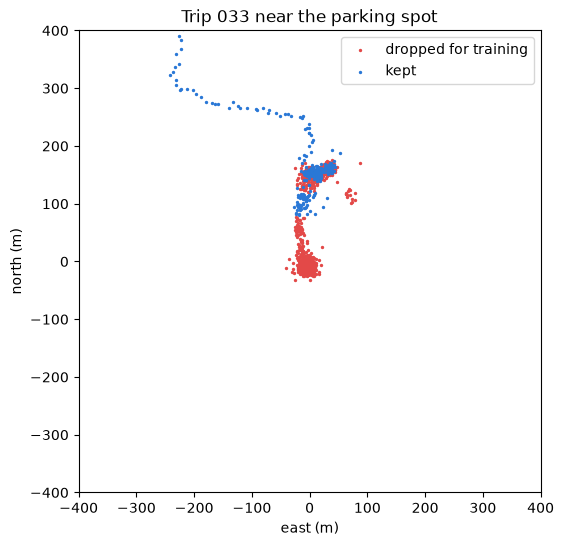

In [7]:
fig, ax = plt.subplots(figsize=(6, 6))
kept = fixes[fixes.keep_train]
dropped = fixes[~fixes.keep_train]
ax.scatter(dropped.x, dropped.y, s=2, c="#e34948", label="dropped for training")
ax.scatter(kept.x, kept.y, s=2, c="#2a78d6", label="kept")
ax.set_aspect("equal"); ax.set_xlim(-400, 400); ax.set_ylim(-400, 400)
ax.set_xlabel("east (m)"); ax.set_ylabel("north (m)"); ax.legend(); ax.set_title("Trip 033 near the parking spot")
plt.show()

## 4. Run on every trip and save

In [8]:
rows = []
for partition in PARTITIONS:
    for trip_dir in sorted(glob.glob(f"{DATA_DIR}/{partition}/*")):
        fixes, arcs_df, proj, summary = clean_trip(partition, trip_dir)
        out = os.path.join(OUT_DIR, partition, summary["trip"])
        os.makedirs(out, exist_ok=True)
        fixes.to_csv(f"{out}/fixes.csv.gz", index=False)
        arcs_df.to_csv(f"{out}/arcs.csv.gz", index=False)
        with open(f"{out}/projection.json", "w") as fh:
            json.dump(proj, fh)
        rows.append(summary)
summary_df = pd.DataFrame(rows).fillna(0)
summary_df.to_csv(f"{OUT_DIR}/cleaning_summary.csv", index=False)
print(f"cleaned {len(summary_df)} trips")

cleaned 90 trips


## 5. Results

In [9]:
train = summary_df[summary_df.partition == "train"]
rules = ["C8_jump", "C4_offroad_dwell", "C7_beyond_route", "C6_far_from_label", "C4_dwell_thinned"]
result = pd.DataFrame({
    "fixes_removed": [int(train[r].sum()) for r in rules],
    "pct_of_train": [round(train[r].sum() / train.fixes.sum() * 100, 2) for r in rules],
    "trips_affected": [int((train[r] > 0).sum()) for r in rules]}, index=rules)
print(f"kept for training: {train.kept_for_training.sum():,} of {train.fixes.sum():,} "
      f"({train.kept_for_training.sum() / train.fixes.sum():.1%})")
result

kept for training: 173,637 of 208,417 (83.3%)


,fixes_removed,pct_of_train,trips_affected
C8_jump,68,0.03,2
C4_offroad_dwell,19487,9.35,8
C7_beyond_route,424,0.20,6
C6_far_from_label,3344,1.60,22
C4_dwell_thinned,11457,5.50,36


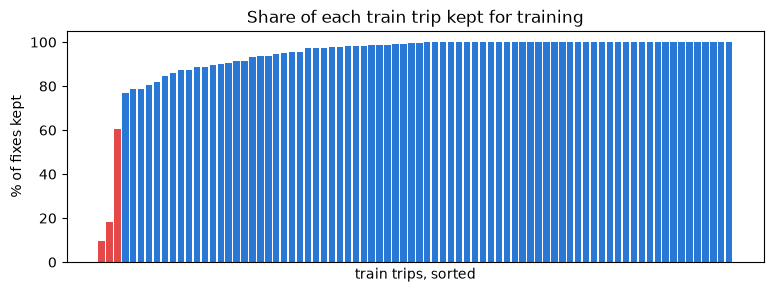

In [10]:
share = (train.kept_for_training / train.fixes * 100).sort_values().values
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(range(len(share)), share, color=["#e34948" if v < 70 else "#2a78d6" for v in share])
ax.set_xticks([]); ax.set_xlabel("train trips, sorted"); ax.set_ylabel("% of fixes kept")
ax.set_title("Share of each train trip kept for training")
plt.show()

In [ ]:
## 6. Sanity checks

If the cleaning did its job, every fix kept for training is close to its label (at most 50 m by construction) and no
position jumps remain.

In [11]:
all_fixes = pd.concat([pd.read_csv(f) for f in glob.glob(f"{OUT_DIR}/train/*/fixes.csv.gz")])
k = all_fixes[all_fixes.keep_train]
print("distance to label of kept fixes: median %.1f m, p95 %.1f m, max %.1f m"
      % (k.d_label.median(), k.d_label.quantile(0.95), k.d_label.max()))
print("position jumps kept:", int(k.jump.sum()))
print(all_fixes.drop_reason.fillna("kept").value_counts())

distance to label of kept fixes: median 4.8 m, p95 15.9 m, max 50.0 m
position jumps kept: 0
drop_reason
kept                 173637
C4_offroad_dwell      19487
C4_dwell_thinned      11457
C6_far_from_label      3344
C7_beyond_route         424
C8_jump                  68
Name: count, dtype: int64


## How to use the output

- **Training:** load `fixes.csv.gz` and keep rows where `keep_train` is true. The label of each fix is `label_arc`.
  Only arcs with `candidate_eligible` should be offered as candidates.
- **Prediction (API):** run only the *always* steps (projection, dt/speeds, segments, heading, dwell and jump flags,
  arc eligibility). Never read `.route` before predicting.
- **Evaluation on student_test:** score all fixes; use the flags only to report results with and without hard cases.